In [ ]:
!date

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import scanpy as sc
import anndata

In [ ]:
sc.set_figure_params(figsize=(5,5), frameon=False)
sc.settings.verbosity = 3

In [ ]:
projdir = '/u/project/cluo/terencew/igvf/2023_YR2/snmCT/rna/'
donors = list(np.loadtxt(f'{projdir}/txt/donors.txt', dtype=str))

In [ ]:
mct = sc.read_h5ad(f'{projdir}/h5ad/raw/mct.filter.h5ad')
multiome = sc.read_h5ad(f'{projdir}/h5ad/raw/multiome.filter.h5ad')

### same metadata for both experiments

In [ ]:
multiome.obs.rename(columns= {'assignment' : 'donor'}, inplace=True)
mct.obs['donor_time'] = [f'{x}_{y}' for x,y in zip(mct.obs['donor'], mct.obs['time'])]

In [ ]:
cols = ['donor', 'time_num', 'donor_time']
multiome.obs = multiome.obs[cols]
mct.obs = mct.obs[cols]
mct.obs['assay'] = 'snmct'
multiome.obs['assay'] = 'multiome'

In [ ]:
mct.var.index = mct.var['symbol']

In [ ]:
mct

In [ ]:
multiome

### problem 1: mCT has MNAR donors for later timepoints
C37 and C38 are bad reprogrammers

In [ ]:
mct_dt = pd.DataFrame(mct.obs['donor_time'].value_counts().sort_index())
mult_dt = pd.DataFrame(multiome.obs['donor_time'].value_counts().sort_index())

dt = pd.concat([mct_dt, mult_dt], axis=1)
dt.columns = ['snmct', 'multiome']

In [ ]:
### absolutely brutal
to_drop = dt[dt['snmct'].isna()].index
to_drop

In [ ]:
mult_mask = [x not in to_drop for x in multiome.obs['donor_time']]
multiome = multiome[mult_mask]

In [ ]:
# multiome.write_h5ad(f'{projdir}/h5ad/raw/multiome_timepoints.h5ad')

### problem 2: we have massive cell imbalance across timepoints
- let's make sure that each timepoint has the same number of cells across each assay
- update to the problem: we need to ensure that the same number of fail/iPSC is being sampled
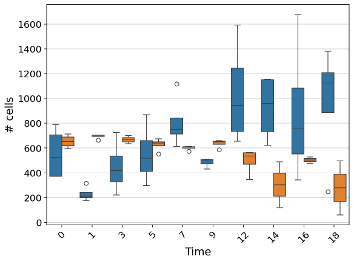

In [ ]:
justin_indir = '/u/project/cluo/Shared_Datasets/IGVF/202208_Pilot/new_multiome/YS3_Testrun3/YS3.v4_Metadata/'
meta_name = 'YS3.v4.metadata.txt'
justin_meta = pd.read_csv(f'{justin_indir}/{meta_name}', sep='\t', header=0, index_col=0)

justin_mask = justin_meta.index.isin(multiome.obs.index)
multiome_mask = multiome.obs.index.isin(justin_meta.index)

multiome.obs['justin_coarse'] = 'NA'
multiome.obs['justin_clusters'] = 'NA'

multiome.obs.loc[multiome_mask, 'justin_coarse'] = justin_meta.reindex(multiome.obs.index)['General_Name']
multiome.obs.loc[multiome_mask, 'justin_clusters'] = justin_meta.reindex(multiome.obs.index)['Name']

In [ ]:
tmp = multiome.obs.melt(id_vars = ['time_num'], value_vars = ['justin_coarse'])

fig, axes = plt.subplots(1, figsize=(6, 6))

x_lab = 'time_num'
hue = 'value'

ax = sns.histplot(data=tmp, x=x_lab,hue=hue, multiple='dodge')
ax.set_xlabel('Cluster', fontsize=16)
ax.set_ylabel('# cells', fontsize=16)
ax.tick_params(axis='x', labelsize=14, labelrotation=45)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.05, 1))

In [ ]:
times = sorted(multiome.obs['time_num'].unique())
assays = ['snmct', 'multiome']
sub_mct_list = []
sub_multiome_list = []
for time in times:
    print(time)
    
    tmp_mct = mct[mct.obs['time_num'] == time]
    tmp_multiome = multiome[multiome.obs['time_num'] == time]

    mct_num = tmp_mct.shape[0]
    multiome_num = tmp_multiome.shape[0]
    
    print(mct_num, multiome_num)

    lower_bound = np.min([mct_num, multiome_num])
    tmp_assay = np.argmax([mct_num, multiome_num])
    
    if tmp_assay == 0:
        sc.pp.subsample(tmp_mct, n_obs=lower_bound, random_state=0)
    else:
        sc.pp.subsample(tmp_multiome, n_obs=lower_bound, random_state=0)
        
    
    sub_mct_list.append(tmp_mct)
    sub_multiome_list.append(tmp_multiome)

In [ ]:
final_mct = anndata.concat(sub_mct_list)
final_multiome = anndata.concat(sub_multiome_list)

In [ ]:
final_mct.shape, final_multiome.shape

In [ ]:
tmp = final_multiome.obs.melt(id_vars = ['time_num'], value_vars = ['justin_coarse'])

fig, axes = plt.subplots(1, figsize=(8, 8))

x_lab = 'time_num'
hue = 'value'

ax = sns.histplot(data=tmp, x=x_lab,hue=hue, multiple='dodge')
ax.set_xlabel('Cluster', fontsize=16)
ax.set_ylabel('# cells', fontsize=16)
ax.tick_params(axis='x', labelsize=14, labelrotation=45)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.05, 1))

In [ ]:
### ok great this works
for time in times:
    print(time)
    tmp_mct = final_mct[final_mct.obs['assay'] == 'snmct']
    tmp_multiome = final_multiome[final_multiome.obs['assay'] == 'multiome']
    print(tmp_mct.obs['time_num'].value_counts()[time],
          tmp_multiome.obs['time_num'].value_counts()[time])

In [ ]:
final_mct.write_h5ad(f'{projdir}/h5ad/raw/mct_subsample.h5ad')
final_multiome.write_h5ad(f'{projdir}/h5ad/raw/multiome_subsample.h5ad')

In [ ]:
!date